# PBL JS04 - Klasterisasi K-Means dan DBSCAN

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js04-klasterisasi)

Notebook ini menerapkan langkah-langkah jobsheet JS04 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS04 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - KMeans: seleksi fitur, plot, SSE, elbow | KMeans pada fitur leksikal terstandardisasi (sampel 20.000) |
| Praktikum 2 - Penerapan KMeans skala besar | MiniBatchKMeans pada seluruh 783.705 URL |
| Praktikum 3 - DBSCAN: compute, evaluasi, visualisasi | DBSCAN + k-distance plot, noise, dan evaluasi |
| Tugas - perbandingan dan evaluasi | Silhouette, ARI, dan NMI terhadap label asli |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1 - Persiapan Data

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
df = pbl_url.load_urls(sample=20000)
X = pbl_url.lexical_features(df['url'])
y = df['type'].to_numpy()
print(df['type'].value_counts().to_dict())

{'benign': 10883, 'phishing': 5860, 'defacement': 2431, 'malware': 602, 'legitimate': 148, 'spam': 70, 'Exploit': 6}


## Langkah 2 - Seleksi Fitur dan Standardisasi

In [3]:
# Fitur biner yang hampir konstan tidak membantu jarak Euclidean; pakai fitur kontinu + indikator utama
features = ['url_len', 'host_len', 'path_len', 'query_len', 'n_dots', 'n_hyphens', 'n_slashes', 'n_equals',
            'n_digits', 'digit_ratio', 'n_subdomains', 'path_depth', 'is_ip', 'has_php', 'entropy', 'host_entropy']
Xs = StandardScaler().fit_transform(np.log1p(X[features].clip(lower=0)))
pca = PCA(2, random_state=42).fit(Xs); P = pca.transform(Xs)
print('Varians dijelaskan PCA-2:', pca.explained_variance_ratio_.round(3))

Varians dijelaskan PCA-2: [0.312 0.182]


Transformasi `log1p` diterapkan sebelum standardisasi karena distribusi panjang dan hitungan karakter sangat menceng (lihat PBL JS02).
Tanpa transformasi ini, beberapa URL yang sangat panjang akan mendominasi jarak Euclidean.

## Langkah 3 - Plot Data

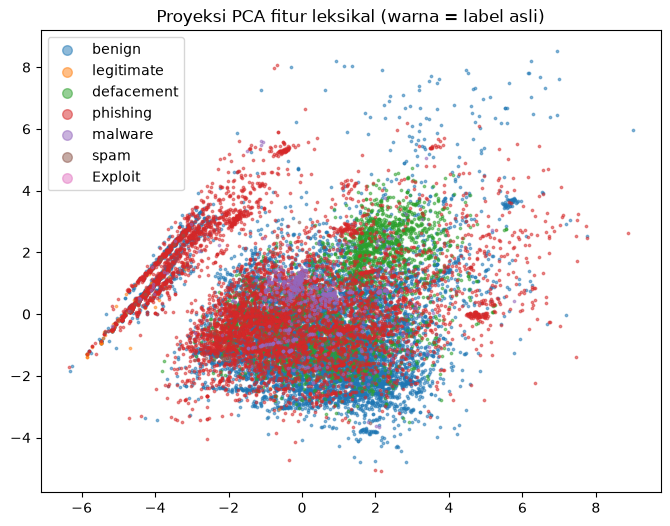

In [4]:
plt.figure(figsize=(8, 6))
for t in pbl_url.CLASSES:
    m = y == t; plt.scatter(P[m, 0], P[m, 1], s=3, alpha=.5, label=t)
plt.legend(markerscale=4); plt.title('Proyeksi PCA fitur leksikal (warna = label asli)'); plt.show()

## Langkah 4-8 - KMeans, SSE, dan Metode Elbow

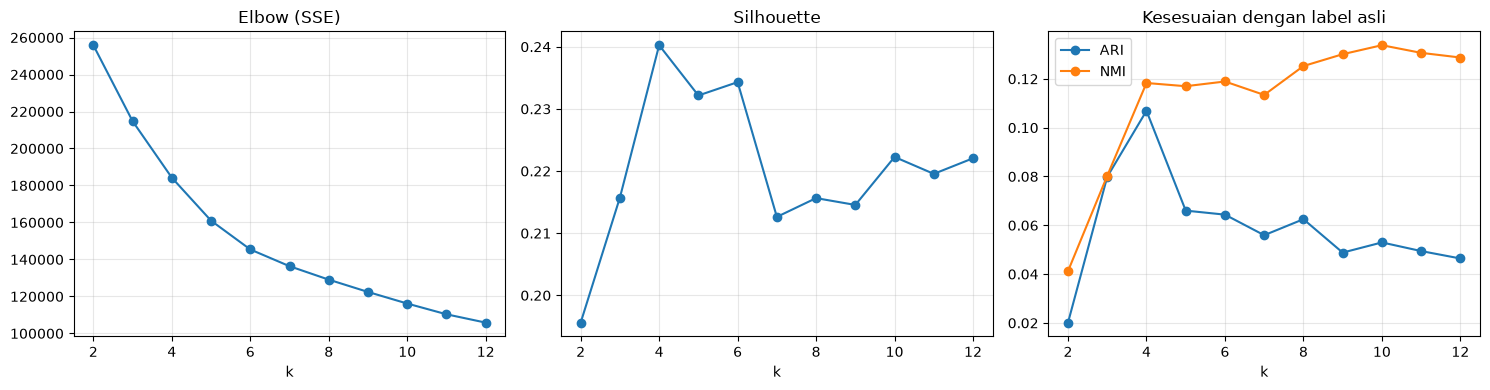

,SSE,silhouette,ARI,NMI
k,,,,
2,255856.7490,0.1956,0.0201,0.0412
3,214788.9541,0.2157,0.0799,0.0803
4,184226.7133,0.2403,0.1069,0.1183
5,160972.0673,0.2322,0.0660,0.1170
6,145401.5565,0.2343,0.0644,0.1189
7,136346.4460,0.2126,0.0559,0.1134
8,129077.1178,0.2156,0.0625,0.1252
9,122421.8581,0.2145,0.0488,0.1301
10,116152.4293,0.2223,0.0530,0.1338


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
rows = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    rows.append({'k': k, 'SSE': km.inertia_, 'silhouette': silhouette_score(Xs, km.labels_, sample_size=8000, random_state=42),
                 'ARI': adjusted_rand_score(y, km.labels_), 'NMI': normalized_mutual_info_score(y, km.labels_)})
elbow = pd.DataFrame(rows).set_index('k')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
elbow['SSE'].plot(ax=ax[0], marker='o', title='Elbow (SSE)'); elbow['silhouette'].plot(ax=ax[1], marker='o', title='Silhouette')
elbow[['ARI', 'NMI']].plot(ax=ax[2], marker='o', title='Kesesuaian dengan label asli')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()
elbow.round(4)

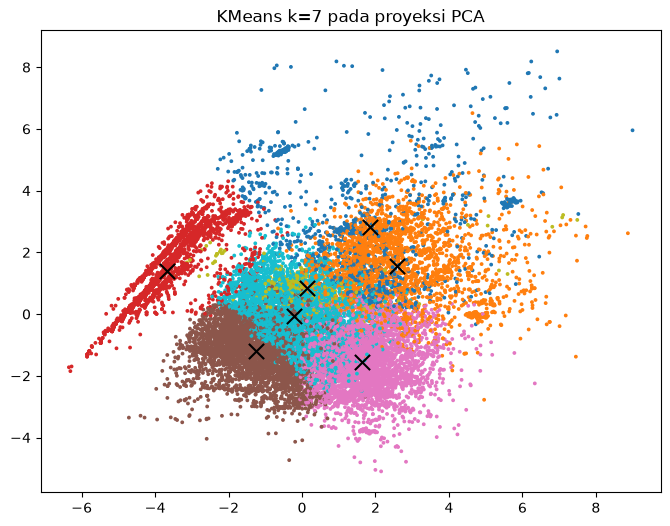

type,Exploit,benign,defacement,legitimate,malware,phishing,spam
klaster,,,,,,,
0,0,518,6,0,53,560,5
1,0,988,1253,0,28,522,0
2,0,1305,0,133,16,1262,9
3,0,2414,344,8,76,1319,23
4,0,3170,358,0,63,574,15
5,6,0,0,0,291,122,0
6,0,2488,470,7,75,1501,18


,url_len,path_len,n_equals,digit_ratio,is_ip,has_php
0,81.31,16.37,0.32,0.16,0.0,0.05
1,96.91,14.60,2.96,0.10,-0.0,0.55
2,19.54,0.02,0.02,0.02,-0.0,0.00
3,28.44,12.98,0.08,0.04,-0.0,0.02
4,70.55,53.59,0.05,0.13,-0.0,0.02
5,27.90,8.32,0.06,0.49,1.0,0.03
6,43.57,21.85,0.03,0.02,-0.0,0.09


In [6]:
K = 7   # jumlah kelas asli; dibandingkan dengan k terbaik silhouette di analisis
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Xs)
plt.figure(figsize=(8, 6)); plt.scatter(P[:, 0], P[:, 1], c=km.labels_, s=3, cmap='tab10')
C = pca.transform(km.cluster_centers_); plt.scatter(C[:, 0], C[:, 1], c='black', marker='x', s=120)
plt.title(f'KMeans k={K} pada proyeksi PCA'); plt.show()
ct = pd.crosstab(pd.Series(km.labels_, name='klaster'), pd.Series(y, name='type'))
display(ct)
profile = pd.DataFrame(np.expm1(StandardScaler().fit(np.log1p(X[features].clip(lower=0))).inverse_transform(km.cluster_centers_)), columns=features)
profile[['url_len', 'path_len', 'n_equals', 'digit_ratio', 'is_ip', 'has_php']].round(2)

## Praktikum 2 - MiniBatchKMeans pada seluruh data

In [7]:
from sklearn.cluster import MiniBatchKMeans
full = pbl_url.load_urls()
Xf = pbl_url.lexical_features(full['url'])
sc_full = StandardScaler().fit(np.log1p(Xf[features].clip(lower=0)))
Xfs = sc_full.transform(np.log1p(Xf[features].clip(lower=0)))
t0 = time.perf_counter(); mbk = MiniBatchKMeans(n_clusters=K, batch_size=4096, n_init=5, random_state=42).fit(Xfs); t_mb = time.perf_counter() - t0
idx = np.random.RandomState(0).choice(len(Xfs), 50000, replace=False)
t0 = time.perf_counter(); km50 = KMeans(n_clusters=K, n_init=5, random_state=42).fit(Xfs[idx]); t_km = time.perf_counter() - t0
print(f'MiniBatchKMeans 783.705 URL: {t_mb:.1f} s | KMeans penuh pada 50.000 URL: {t_km:.1f} s')
print('ARI MiniBatchKMeans vs label asli (seluruh data):', round(adjusted_rand_score(full['type'], mbk.labels_), 4))
print('Kesepakatan MiniBatch vs KMeans pada 50k sampel (ARI):', round(adjusted_rand_score(km50.labels_, mbk.predict(Xfs[idx])), 4))
pd.crosstab(pd.Series(mbk.labels_, name='klaster'), full['type'], normalize='columns').round(3)

MiniBatchKMeans 783.705 URL: 1.3 s | KMeans penuh pada 50.000 URL: 0.1 s


ARI MiniBatchKMeans vs label asli (seluruh data): 0.0516
Kesepakatan MiniBatch vs KMeans pada 50k sampel (ARI): 0.7544


type,Exploit,benign,defacement,legitimate,malware,phishing,spam
klaster,,,,,,,
0,0.000,0.177,0.152,0.054,0.043,0.210,0.215
1,0.000,0.093,0.516,0.001,0.045,0.093,0.000
2,0.000,0.118,0.000,0.870,0.042,0.228,0.109
3,0.004,0.272,0.177,0.067,0.142,0.274,0.411
4,0.996,0.000,0.000,0.000,0.499,0.020,0.000
5,0.000,0.093,0.015,0.003,0.187,0.119,0.074
6,0.000,0.246,0.140,0.005,0.043,0.056,0.192


## Praktikum 3 - DBSCAN

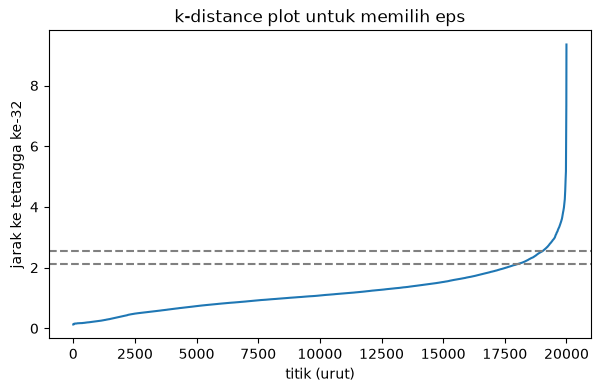

,n_klaster,noise_%,silhouette_non_noise,ARI_semua,NMI_semua
eps,,,,,
0.80,38,57.335,0.2429,0.0034,0.1170
1.00,24,39.220,0.1514,0.0238,0.1262
1.25,19,23.680,0.1377,0.0764,0.1376
1.50,17,14.400,0.1518,0.0856,0.1314
2.00,5,4.955,0.2483,0.1452,0.1446


In [8]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
MIN_SAMPLES = 2 * len(features)
d, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xs).kneighbors(Xs)
kdist = np.sort(d[:, -1])
plt.figure(figsize=(7, 4)); plt.plot(kdist); plt.ylabel(f'jarak ke tetangga ke-{MIN_SAMPLES}'); plt.xlabel('titik (urut)')
for q in [0.90, 0.95]: plt.axhline(np.quantile(kdist, q), ls='--', c='gray')
plt.title('k-distance plot untuk memilih eps'); plt.show()
rows = []
for eps in [0.8, 1.0, 1.25, 1.5, 2.0]:
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Xs)
    m = lab != -1
    rows.append({'eps': eps, 'n_klaster': len(set(lab)) - (-1 in lab), 'noise_%': 100 * (~m).mean(),
                 'silhouette_non_noise': silhouette_score(Xs[m], lab[m], sample_size=min(8000, m.sum()), random_state=0) if len(set(lab[m])) > 1 else np.nan,
                 'ARI_semua': adjusted_rand_score(y, lab), 'NMI_semua': normalized_mutual_info_score(y, lab)})
db_tbl = pd.DataFrame(rows).set_index('eps'); db_tbl.round(4)

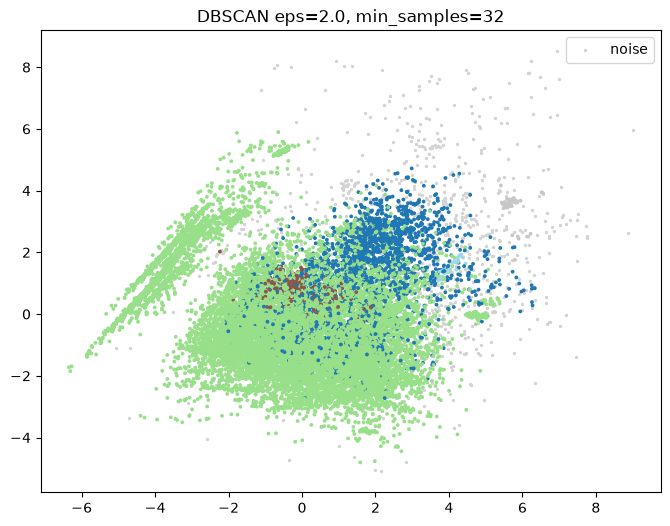

Persentase noise per kelas asli:
{'Exploit': 16.67, 'benign': 4.32, 'defacement': 1.6, 'legitimate': 0.68, 'malware': 3.65, 'phishing': 7.82, 'spam': 0.0}


type,Exploit,benign,defacement,legitimate,malware,phishing,spam
klaster_dbscan,,,,,,,
-1,1,470,39,1,22,458,0
0,0,592,1263,0,13,555,1
1,0,9745,1129,147,278,4767,69
2,5,0,0,0,289,73,0
3,0,43,0,0,0,7,0
4,0,33,0,0,0,0,0


In [9]:
EPS = db_tbl['NMI_semua'].idxmax()
lab = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Xs)
plt.figure(figsize=(8, 6)); plt.scatter(P[lab == -1, 0], P[lab == -1, 1], c='lightgray', s=2, label='noise')
plt.scatter(P[lab != -1, 0], P[lab != -1, 1], c=lab[lab != -1], s=3, cmap='tab20'); plt.legend()
plt.title(f'DBSCAN eps={EPS}, min_samples={MIN_SAMPLES}'); plt.show()
noise_by_class = pd.Series(lab == -1).groupby(y).mean().mul(100).round(2)
print('Persentase noise per kelas asli:'); print(noise_by_class.to_dict())
top = pd.Series(lab[lab != -1]).value_counts().index[:8]
pd.crosstab(pd.Series(lab, name='klaster_dbscan').where(lambda s: s.isin(top) | (s == -1), 99), pd.Series(y, name='type'))

## Perbandingan KMeans vs DBSCAN

**KMeans.** Kurva SSE turun landai tanpa siku yang tegas (255.857 pada k=2 → 105.835 pada k=12). Silhouette tertinggi di **k=4** (0,240), tetapi nilainya tetap rendah: di bawah 0,25 berarti struktur klaster lemah (Rousseeuw, 1987). Kesesuaian dengan label asli juga rendah, dengan ARI maksimum 0,107 (k=4) dan NMI 0,12-0,13.

Profil centroid k=7 tetap bermakna secara domain:

| Klaster | Ciri centroid | Isi dominan |
| --- | --- | --- |
| 5 | `is_ip` = 1, rasio digit 0,49 | **semua 6 Exploit**, 291 malware, 122 phishing |
| 1 | `n_equals` 2,96, `.php` 55%, panjang 97 | 1.253 dari 2.431 **defacement** |
| 2 | domain saja (path ≈ 0, panjang 20) | **semua 133 legitimate** + benign/phishing berdomain pendek |
| 0, 3, 4, 6 | variasi panjang path | campuran benign dan phishing |

KMeans menemukan **tipe struktur URL** (URL ke IP, URL CMS dengan query, domain saja), bukan tingkat bahaya. Phishing dan benign tidak dapat dipisahkan karena struktur URL-nya mirip. Phishing sengaja meniru URL normal, dan pembedanya ada pada token (nama merek, kata `login`), yang tidak tercakup oleh fitur jarak Euclidean.

**MiniBatchKMeans** (Sculley, 2010) mengelompokkan seluruh 783.705 URL hanya dalam 1,3 detik. Kesepakatannya dengan KMeans penuh pada 50 ribu sampel adalah ARI 0,754, sehingga partisinya mirip tetapi tidak identik. Pada data penuh, satu klaster berisi 99,6% Exploit dan 49,9% malware, dan klaster lain berisi 87% legitimate. Pola IP-malware dan domain-saja tetap stabil pada skala penuh.

**DBSCAN.** Pemilihan `eps` sulit karena kepadatan antarkelas berbeda. Dengan `eps` = 0,8, 57% titik menjadi noise dan terbentuk 38 klaster kecil. Dengan `eps` = 2,0, noise tinggal 5% dan NMI tertinggi (0,145, ARI 0,145), tetapi hampir semua benign, phishing, dan spam bergabung dalam satu klaster besar (klaster 1: 9.745 benign + 4.767 phishing). DBSCAN tetap memisahkan klaster **IP-malware** (klaster 2: 5 Exploit + 289 malware + 73 phishing) dan klaster **defacement** (klaster 0). Noise tertinggi ada pada Exploit (16,7%) dan phishing (7,8%), yaitu kelas dengan URL yang paling bervariasi.

**Kesimpulan:** KMeans dan DBSCAN menghasilkan kualitas klaster serupa (silhouette 0,2-0,25, ARI ≤ 0,15). Clustering tanpa label **tidak dapat menggantikan klasifikasi** untuk mendeteksi URL berbahaya, tetapi berguna untuk eksplorasi. Klaster IP + ekstensi biner dapat langsung dipakai sebagai aturan deteksi malware/Exploit. Ester dkk. (1996) menekankan bahwa DBSCAN unggul pada klaster berbentuk sembarang dengan kepadatan seragam. Kepadatan data URL ini justru sangat beragam, kondisi yang ditangani HDBSCAN di PBL JS05.

## Rujukan

1. Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory*, 28(2), 129-137. https://doi.org/10.1109/TIT.1982.1056489
2. Sculley, D. (2010). Web-scale k-means clustering. *Proceedings of the 19th International Conference on World Wide Web (WWW)*, 1177-1178. https://doi.org/10.1145/1772690.1772862
3. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of the 2nd International Conference on Knowledge Discovery and Data Mining (KDD)*, 226-231.
4. Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65. https://doi.org/10.1016/0377-0427(87)90125-7
5. Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193-218. https://doi.org/10.1007/BF01908075
6. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
7. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30